# Table of Contents

- [1. Gravimetric Modeling](#1-gravimetric-modeling)
  - [1.1 Importing Packages](#11-importing-packages)
  - [1.0.delta_rho Gravimetric Validation](#10.delta_rho-gravimetric-validation)
    - [1.delta_rho.1 Forward Modeling](#1delta_rho1-forward-modeling)
    - [1.delta_rho.delta_rho Creating Synthetic Data Parameters](#1delta_rhodelta_rho-creating-synthetic-data-parameters)
    - [1.delta_rho.3 Comparison: Prisms vs Circle and Cylinder](#1delta_rho3-comparison-prisms-vs-circle-and-cylinder)


# Gravimetric Modeling

### Importing Packages

In [6]:
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patches as patches
import math
import cmath 
from decimal import Decimal
import sympy as sp 
from matplotlib.patches import Circle

import sys
np.set_printoptions(
                   edgeitems=10, linewidth=50)


### Gravimetric Validation

#### Foward Modeling

In [14]:
def gvertical(vecx, R, xq, z1, z2, t):

    gz = np.zeros(len(vecx), dtype=float)

    # Safe evaluation of the logarithmic term
    def safe_log(vecx, xq, z1, z2, t, i):

        # First logarithmic term
        try:
            ln1 = math.log(
                (z2**2 + (vecx[i]-xq)**2) /
                (z1**2 + (vecx[i]-xq)**2)
            )
        except (ValueError, ZeroDivisionError, OverflowError):
            ln1 = 0.0

        # Second logarithmic term
        try:
            ln2 = math.log(
                (z1**2 + ((vecx[i]-xq)-t)**2) /
                (z2**2 + ((vecx[i]-xq)-t)**2)
            )
        except (ValueError, ZeroDivisionError, OverflowError):
            ln2 = 0.0

        return ln1, ln2
    

    def safe_atan(vecx, xq, z1, z2, t, i):

        # First arctangent
        try:
            atan1 = math.atan(((vecx[i]-xq)-t)/z2)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan1 = 0.0

        # Second arctangent
        try:
            atan2 = math.atan((vecx[i]-xq)/z2)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan2 = 0.0

        # Third arctangent
        try:
            atan3 = math.atan(((vecx[i]-xq)-t)/z1)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan3 = 0.0

        # Fourth arctangent
        try:
            atan4 = math.atan((vecx[i]-xq)/z1)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan4 = 0.0

        return atan1, atan2, atan3, atan4


    for i in range(len(gz)):

        ln1, ln2 = safe_log(vecx, xq, z1, z2, t, i)

        atan1, atan2, atan3, atan4 = safe_atan(vecx, xq, z1, z2, t, i)

        gz[i] = (2*G*R) * (
            ((vecx[i]-xq)/2) * ln1 +
            (((vecx[i]-xq)-t)/2) * ln2 -
            z2 * ( atan1 - atan2) +
            z1 * ( atan3 - atan4 )
        )
    return gz


In [15]:
def automatic_gv_curve(densidades, vecx, xq, z1, z2, t_size):
    final_curve = np.zeros(len(vecx), dtype=float)
    prisms_by_layer = len(xq) 
    counter = 0 
    
    for d in densidades:
        for i, j in enumerate(d):
            idx_camada = counter // prisms_by_layer
            if idx_camada >= len(z1):
                break
            final_curve += gvertical(vecx, j, xq[i], z1[idx_camada], z2[idx_camada], t_size)
            counter += 1

    return final_curve 

#### Creating Syntetic Data parameters

In [ ]:
# x parameter
vecx=np.arange(0.1,8,0.2) #km


# Universal gravitational constant 
G = 6.67430 # 6.67430* 1e-11 * 1e11(mGal)


z1=np.arange(0,1,0.05) # km
z2=np.arange(0.5,1.05,0.05) #km
xq=np.arange(0,8,0.2) #km

t=0.2 #km



In [18]:
# x parameter
vecx = np.arange(0.1, 8, 0.2)  # km

# Universal gravitational constant
G = 6.67430  # 6.67430* 1e-11 * 1e11(mGal)

# Prism geometry
z1 = np.arange(0, 1, 0.05)       # Upper boundary (km)
z2 = np.arange(0.05, 1.05, 0.05) # Lower boundary (km)

xq = np.arange(0, 8, 0.2)        # km
t = 0.2                         # km

#### Comparison Prisms with Circle and Cylinder

/var/folders/k3/x8nlh6915zq2d41sjcfp015m0000gn/T/ipykernel_93864/286108021.py:45: RuntimeWarning: divide by zero encountered in scalar divide
  atan3 = math.atan(((vecx[i]-xq)-t)/z1)
/var/folders/k3/x8nlh6915zq2d41sjcfp015m0000gn/T/ipykernel_93864/286108021.py:51: RuntimeWarning: divide by zero encountered in scalar divide
  atan4 = math.atan((vecx[i]-xq)/z1)


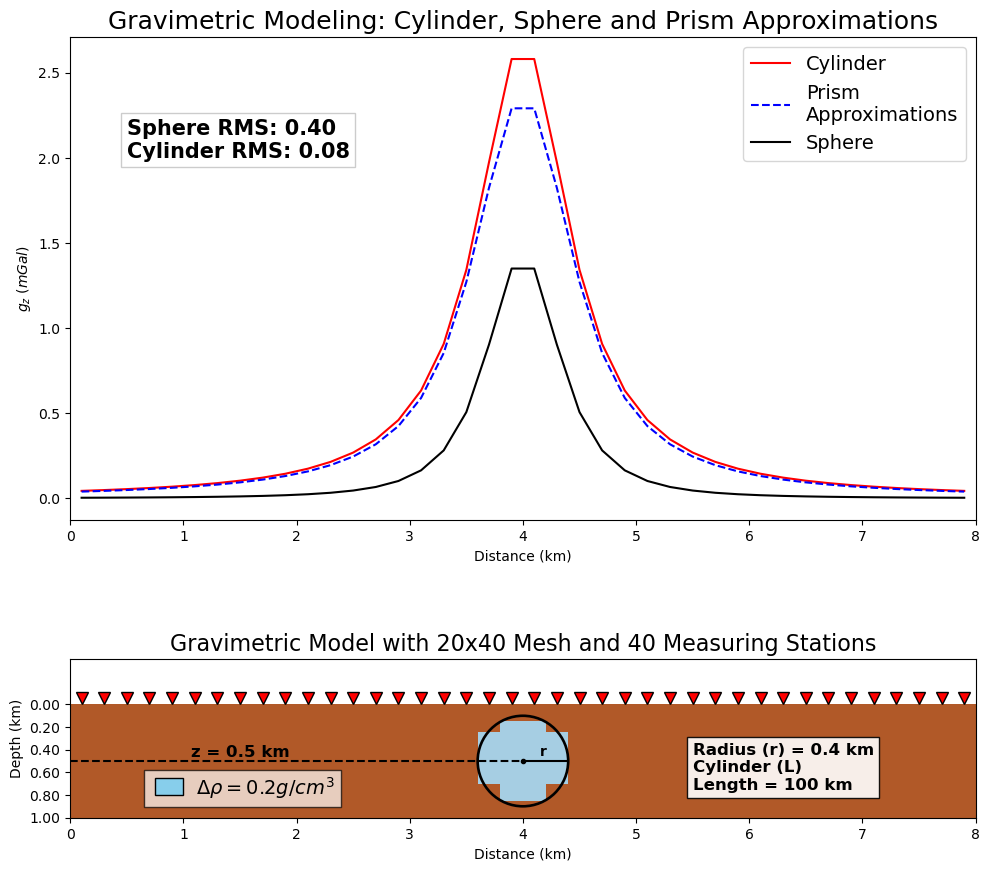

In [25]:
# Sphere parameters
R = 0.4             # Radius of the sphere (km)
delta_rho = 0.2      # Density contrast (g/cm³)
z = 0.5            # Depth to the center of the sphere (km)
L = 100            # Length of the cylinder (km)

# Define x-axis values (station positions)
x_min = 0
x_max = 8
n_points = 40         # Number of stations
# x_values = np.linspace(x_min, x_max, n_points)

# Density mesh (20 rows x 40 columns)
densidades_malha = [
    [0] * 40,
    [0] * 40,
    [0] * 40,
    [0] * 19 + [0.2, 0.2] + [0] * 19,
    [0] * 19 + [0.2, 0.2] + [0] * 19,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 18 + [0.2] * 4 + [0] * 18,
    [0] * 19 + [0.2, 0.2] + [0] * 19,
    [0] * 19 + [0.2, 0.2] + [0] * 19,
    [0] * 19 + [0.2, 0.2] + [0] * 19,
    [0] * 40,
    [0] * 40,
    [0] * 40
]

density_mesh = np.asarray(densidades_malha, dtype=float)


# --- Gravimetric modeling ---

# Cylinder response
gz_cylinder = (
    (2 * np.pi * G * delta_rho * R**2)
    / (z * (1 + ((vecx - 4)**2 / z**2)))
    * (1 / np.sqrt(
        1 + (((vecx - 4)**2 + z**2) / L**2)
    ))
)

# Sphere response
gz_sphere = (
    (4*math.pi * G * delta_rho * (R**3) * z) / 
    (3*(((vecx - 4)**2 + z**2)**1.5))
    ) 


# Prism response (you must define vecx, xq, z1, z2, t, and automatic_gv_curve)
gz_prisms = automatic_gv_curve(density_mesh, vecx, xq, z1, z2, t)

# RMS errors
rms_cylinder = np.sqrt(np.mean((gz_cylinder - np.array(gz_prisms))**2))
rms_sphere = np.sqrt(np.mean((gz_sphere - np.array(gz_prisms))**2))

# --- Plotting ---
plt.figure(figsize=(10, 10))

# Plot 1: Gravimetric curves
plt.subplot(2, 1, 1)
plt.plot(vecx, gz_cylinder, color='red', label='Cylinder')
plt.plot(vecx, gz_prisms, color='blue', label='Prism\nApproximations', linestyle='--')
plt.plot(vecx, gz_sphere, color='black', label='Sphere')

plt.xlabel('Distance (km)')
plt.ylabel(r'$g_z$ $(mGal)$')
plt.title('Gravimetric Modeling: Cylinder, Sphere and Prism Approximations', fontsize=18)
plt.legend(loc='upper right', fontsize=14)

# Custom x-ticks
plt.xticks(np.arange(0, 9, 1))
plt.xlim(0, 8)

# RMS text
plt.text(0.5, 2, f'Sphere RMS: {rms_sphere:.2f}\nCylinder RMS: {rms_cylinder:.2f}', 
         fontsize=15, color='black', fontweight='bold', 
         bbox=dict(facecolor='white', alpha=0.2, edgecolor='black'))

# Plot 2: 2D Model with density contrast
plt.subplot(2, 1, 2)
pastel_reversed = plt.get_cmap('Paired').reversed()
plt.imshow(density_mesh, extent=[0, 8, 1, 0], cmap=pastel_reversed, aspect=1/1)

# Stations (measurement positions)
vecyy = np.zeros_like(vecx) - 0.06
plt.plot(vecx, vecyy, "v", markersize=8, color='red', markeredgecolor='black')

# Draw sphere
circle1 = plt.Circle((4, 0.5), 0.4, edgecolor='black', facecolor='none', lw=1.9)
plt.gca().add_patch(circle1)


# Dashed line indicating the depth of the sphere center
plt.plot(
    [0, 4], [z, z],
    linestyle='--',
    color='black',
    linewidth=1.5,
    zorder=12
)

# Depth annotation
plt.text(
    1.5, z - 0.035,
    f'z = {z:.1f} km',
    fontsize=12,
    color='black',
    fontweight='bold',
    ha='center'
)

# Labels and limits
plt.xlim((0, 8))
plt.ylim((1.001, -0.4))
y_vals = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
y_labels = ['0.00', '0.20', '0.40', '0.60', '0.80', '1.00']
plt.yticks(y_vals, y_labels)

plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Gravimetric Model with 20x40 Mesh and 40 Measuring Stations', fontsize=16)

# Annotations
plt.text(5.5, 0.75, 'Radius (r) = 0.4 km\nCylinder (L)\nLength = 100 km',
         fontsize=12, color='black', fontweight='bold', 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='black'))

# Arrow from sphere center to boundary
plt.plot([4, 4.4], [0.5, 0.5], marker='none', color='black')
plt.plot(4, 0.5, marker='o', color='black', markersize=3)
plt.text(4.15, 0.45, 'r', fontsize=10, color='black', fontweight='bold')

# Density annotation
plt.text(0.7, 0.8, r'       $\Delta\rho=0.2 g/cm^3$', fontsize=14, 
         color='black', fontweight='bold', 
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black'))

# Add blue rectangle
rectangle = plt.Rectangle((0.75, 0.65), 0.25, 0.15, facecolor='skyblue', 
                          edgecolor='black', linewidth=1, zorder=10)
plt.gca().add_patch(rectangle)

# Final layout
plt.tight_layout()
plt.show()
